# 4 · Results and cost

Every number in the talk's result slides, read from the files the training runs wrote (`weights/*.json`,
`weights/bench.json`), plus one model re-scored live to show the files reproduce.

In [1]:
import sys, json, time, math
from pathlib import Path
ROOT = Path.cwd().parent            # demo/vpt
sys.path.insert(0, str(ROOT))
import numpy as np, torch
print("torch", torch.__version__, "| CUDA:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

torch 2.11.0+cu128 | CUDA: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [2]:
W = ROOT / "weights"
TASKS = {"dermamnist": "Skin lesion", "bloodmnist": "Blood cell", "pneumoniamnist": "Chest X-ray"}
METHODS = {"linear": "linear", "vpt": "vpt-deep-p50", "full": "full"}
R = {(t, m, r): json.loads((W / f"{t}_{tag}_{r}.json").read_text()) for t in TASKS for m, tag in METHODS.items() for r in ("1k", "full")}
print(f"{'task':12s}{'method':8s}{'images':>8s}{'acc':>8s}{'bal acc':>9s}{'AUC':>8s}{'stored':>11s}")
for t, name in TASKS.items():
    for r in ("1k", "full"):
        for m, tag in METHODS.items():
            e = R[(t, m, r)]; size = (W / f"{t}_{tag}_{r}.safetensors").stat().st_size if (W / f"{t}_{tag}_{r}.safetensors").exists() else 343_230_000
            print(f"{name:12s}{m:8s}{e['train_images']:>8,}{e['test']['acc']:>8.1f}{e['test']['bal_acc']:>9.1f}{e['test']['auc'] / 100:>8.3f}{size / 1e6:>9.2f} MB")
        print()

task        method    images     acc  bal acc     AUC     stored
Skin lesion linear     1,000    75.1     58.4   0.928     0.02 MB
Skin lesion vpt        1,000    79.4     63.3   0.927     1.86 MB
Skin lesion full       1,000    78.8     64.9   0.939   343.23 MB

Skin lesion linear     7,007    83.0     68.1   0.964     0.02 MB
Skin lesion vpt        7,007    88.3     81.0   0.983     1.86 MB
Skin lesion full       7,007    91.2     84.4   0.987   343.23 MB

Blood cell  linear     1,000    96.0     96.1   0.998     0.02 MB
Blood cell  vpt        1,000    98.1     98.2   0.999     1.87 MB
Blood cell  full       1,000    97.6     98.0   0.999   343.23 MB

Blood cell  linear    11,959    97.4     97.3   0.999     0.02 MB
Blood cell  vpt       11,959    99.1     99.1   1.000     1.87 MB
Blood cell  full      11,959    99.1     99.2   1.000   343.23 MB

Chest X-ray linear     1,000    91.3     89.2   0.978     0.01 MB
Chest X-ray vpt        1,000    91.8     89.7   0.985     1.85 MB
Chest X

## How each method scales with data

Balanced accuracy at 1,000 training images and on the full training split. VPT is above the linear probe in
all six settings and within about four points of full fine-tuning.

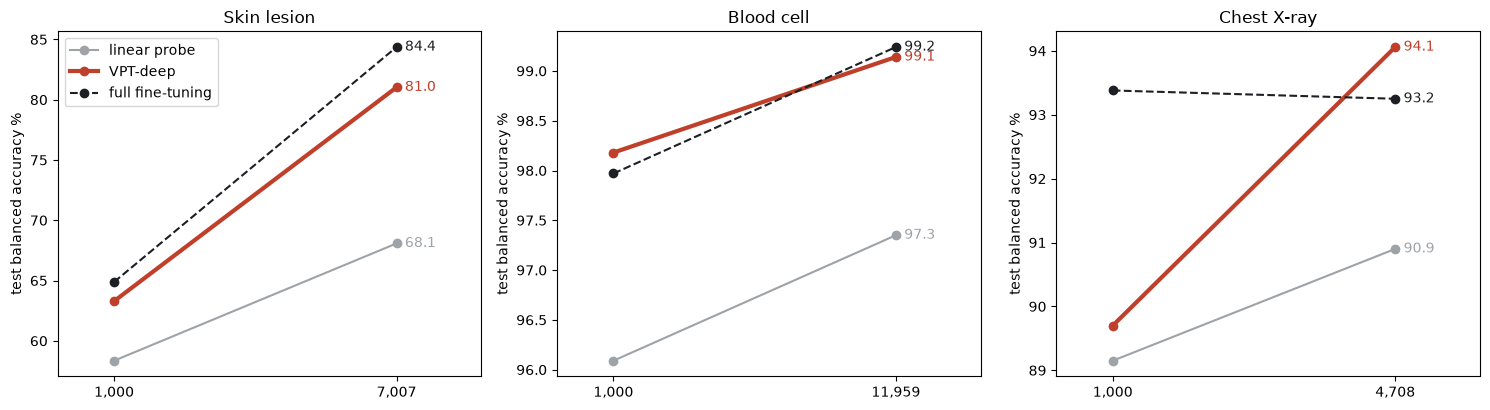

Skin lesion    1k: VPT - linear  +4.9   VPT - full  -1.6
Skin lesion  full: VPT - linear +13.0   VPT - full  -3.3
Blood cell     1k: VPT - linear  +2.1   VPT - full  +0.2
Blood cell   full: VPT - linear  +1.8   VPT - full  -0.1
Chest X-ray    1k: VPT - linear  +0.5   VPT - full  -3.7
Chest X-ray  full: VPT - linear  +3.2   VPT - full  +0.8


In [3]:
import matplotlib.pyplot as plt
style = {"linear": dict(color="#9EA3A8", ls="-", label="linear probe"), "vpt": dict(color="#BF3F2A", ls="-", lw=3, label="VPT-deep"), "full": dict(color="#1C1F23", ls="--", label="full fine-tuning")}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (t, name) in zip(axes, TASKS.items()):
    for m in METHODS:
        a = [R[(t, m, "1k")]["test"]["bal_acc"], R[(t, m, "full")]["test"]["bal_acc"]]
        ax.plot([0, 1], a, marker="o", **style[m])
        ax.annotate(f"{a[1]:.1f}", (1, a[1]), xytext=(6, 0), textcoords="offset points", va="center", color=style[m]["color"])
    ax.set_xticks([0, 1], ["1,000", f"{R[(t, 'vpt', 'full')]['train_images']:,}"]); ax.set_xlim(-0.2, 1.3)
    ax.set_title(name); ax.set_ylabel("test balanced accuracy %")
axes[0].legend(); plt.tight_layout(); plt.show()
for t, name in TASKS.items():
    for r in ("1k", "full"):
        l, v, f = (R[(t, m, r)]["test"]["bal_acc"] for m in METHODS)
        print(f"{name:12s}{r:>5s}: VPT - linear {v - l:+5.1f}   VPT - full {v - f:+5.1f}")

## What each method costs

`bench.py` measured training memory and time at batch 32 (bf16, RTX 5070 Ti laptop GPU) and inference on 2 CPU
threads, under identical conditions. VPT backpropagates through the whole frozen model to reach its prompts,
so it trains at close to full fine-tuning's cost; it is the only method that is slower at inference, because
of its 50 extra tokens per layer. Its saving is storage: 1.9 MB per task instead of 343 MB.

In [4]:
b = json.loads((W / "bench.json").read_text())
print(f"GPU: {b['gpu']} | batch {b['train_batch']} | CPU threads {b['cpu_threads']}\n")
print(f"{'method':8s}{'train GB':>10s}{'train ms/img':>14s}{'CPU ms/img':>12s}{'minutes, Derma full split':>28s}")
for m, tag in METHODS.items():
    e = b[m]; mins = R[("dermamnist", m, "full")]["train_minutes"]
    print(f"{m:8s}{e['train_peak_gb']:>10.2f}{e['train_ms_per_img']:>14.2f}{e['cpu_ms_per_img']:>12d}{mins:>28.1f}")

GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU | batch 32 | CPU threads 2

method    train GB  train ms/img  CPU ms/img   minutes, Derma full split
linear        0.48          1.29         185                         4.8
vpt           2.28          4.16         227                        13.7
full          3.49          5.01         190                        20.4


## Re-scoring a saved model

Loads the VPT-deep prompt file of DermaMNIST (full split) onto the base model and scores the whole test split
again. `evaluate.py` does this for all 18 models; every one reproduced its stored numbers.

In [5]:
from torch.utils.data import DataLoader
from torchvision import transforms
from safetensors.torch import load_file
from train import build, evaluate
from vpt_model import VPTViT
sets, classes = build("dermamnist", transforms.Normalize([0.5] * 3, [0.5] * 3))
model = VPTViT(len(classes), num_prompts=50).cuda()
model.load_state_dict(load_file(W / "dermamnist_vpt-deep-p50_full.safetensors"), strict=False)
t0 = time.time()
got = evaluate(model, DataLoader(sets["test"], batch_size=128, num_workers=0), "cuda", len(classes))
print("stored   ", R[("dermamnist", "vpt", "full")]["test"])
print("re-scored", got, f"({time.time() - t0:.0f}s for {len(sets['test'])} images)")

stored    {'acc': 88.28, 'bal_acc': 81.03, 'auc': 98.28}
re-scored {'acc': 88.28, 'bal_acc': 81.03, 'auc': 98.28} (5s for 2005 images)
